# Galerie du test : images, transcriptions et prédictions

Ce notebook visualise des images du split officiel de test avec leur transcription de référence et, si disponible, la prédiction du checkpoint. Il ne modifie pas les données et ne réentraîne pas le modèle.

In [1]:
from pathlib import Path
import json
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from rapidfuzz.distance import Levenshtein

def locate_project():
    for root in [Path.cwd(), *Path.cwd().parents]:
        if (root / 'work' / 'data' / 'gazette' / 'test.jsonl').is_file():
            return root
    raise FileNotFoundError('Projet introuvable : lancez Jupyter depuis le projet ou ses sous-dossiers.')

PROJECT = locate_project()
DATA = PROJECT / 'work' / 'data' / 'gazette'
RUN = PROJECT / 'outputs' / 'arabic_ocr' / 'runs' / 'baseline'
print('Projet :', PROJECT)
print('Test :', DATA / 'test.jsonl')
print('Run :', RUN)

Projet : C:\Users\sail_\Documents\Codex\2026-10-29\oui-il-existe-des-datasets-adapt
Test : C:\Users\sail_\Documents\Codex\2026-10-29\oui-il-existe-des-datasets-adapt\work\data\gazette\test.jsonl
Run : C:\Users\sail_\Documents\Codex\2026-10-29\oui-il-existe-des-datasets-adapt\outputs\arabic_ocr\runs\baseline


In [2]:
test_rows = [json.loads(line) for line in (DATA / 'test.jsonl').read_text(encoding='utf-8').splitlines() if line.strip()]
pred_path = RUN / 'test' / 'predictions.jsonl'
predictions = {}
if pred_path.is_file():
    predictions = {row['id']: row for row in (json.loads(line) for line in pred_path.read_text(encoding='utf-8').splitlines() if line.strip())}

records = []
for row in test_rows:
    item = dict(row)
    item['prediction'] = predictions.get(row['id'], {}).get('prediction', '')
    item['line_cer'] = Levenshtein.distance(row['text'], item['prediction']) / max(1, len(row['text'])) if item['prediction'] else np.nan
    with Image.open(row['image']) as image:
        item['width_px'], item['height_px'] = image.size
    records.append(item)

df = pd.DataFrame(records)
print(f"{len(df)} images chargées ; {df['prediction'].ne('').sum()} prédictions associées.")
df[['id', 'text', 'prediction', 'line_cer', 'width_px', 'height_px']].head(3)

1212 images chargées ; 1212 prédictions associées.

,id,text,prediction,line_cer,width_px,height_px
0,1 (11)__page_004__region_005_line_0008.png,لهذه المناطق؛,لتذه المناطق؛,0.076923,142,33
1,1 (11)__page_004__region_005_line_0016.png,"ه) يشمل لفظ ""شخص"" الشخص الذاتي والشركة وشركة ا...","ه) يشمل لفظ ""شخص""، الشخص الذاتي والشركة وشركة ...",0.012500,968,40
2,1 (11)__page_004__region_005_line_0018.png,"ز) تعني عبارتا ""مقاولة دولة متعاقدة"" و ""مقاولة...","ز) تعني عبارتا ""مقاولة دولة متعاقد"" و امقاولة ...",0.020408,971,40


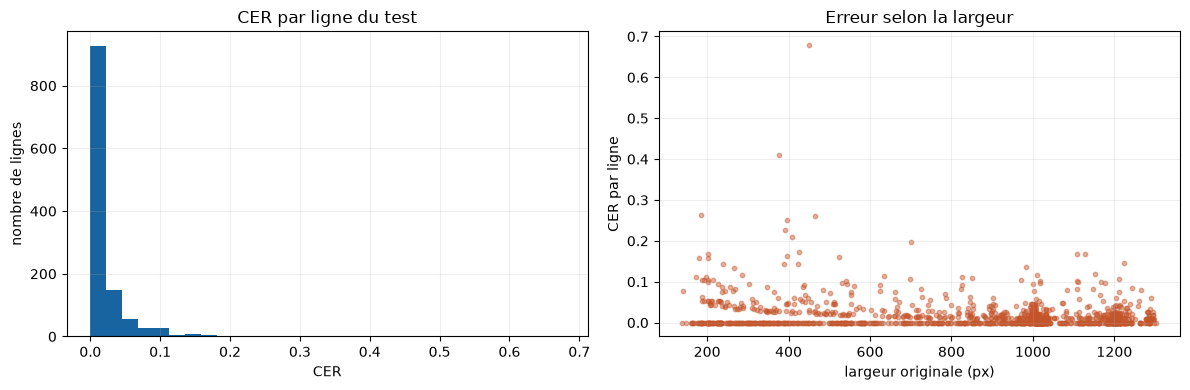

In [3]:
if df['line_cer'].notna().any():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(df['line_cer'].dropna(), bins=30, color='#1764a0')
    axes[0].set(title='CER par ligne du test', xlabel='CER', ylabel='nombre de lignes')
    axes[1].scatter(df['width_px'], df['line_cer'], s=10, alpha=.45, color='#c4552b')
    axes[1].set(title='Erreur selon la largeur', xlabel='largeur originale (px)', ylabel='CER par ligne')
    for axis in axes: axis.grid(alpha=.2)
    plt.tight_layout()
    plt.show()
else:
    print('Aucune prédiction trouvée : le notebook affiche uniquement les références.')

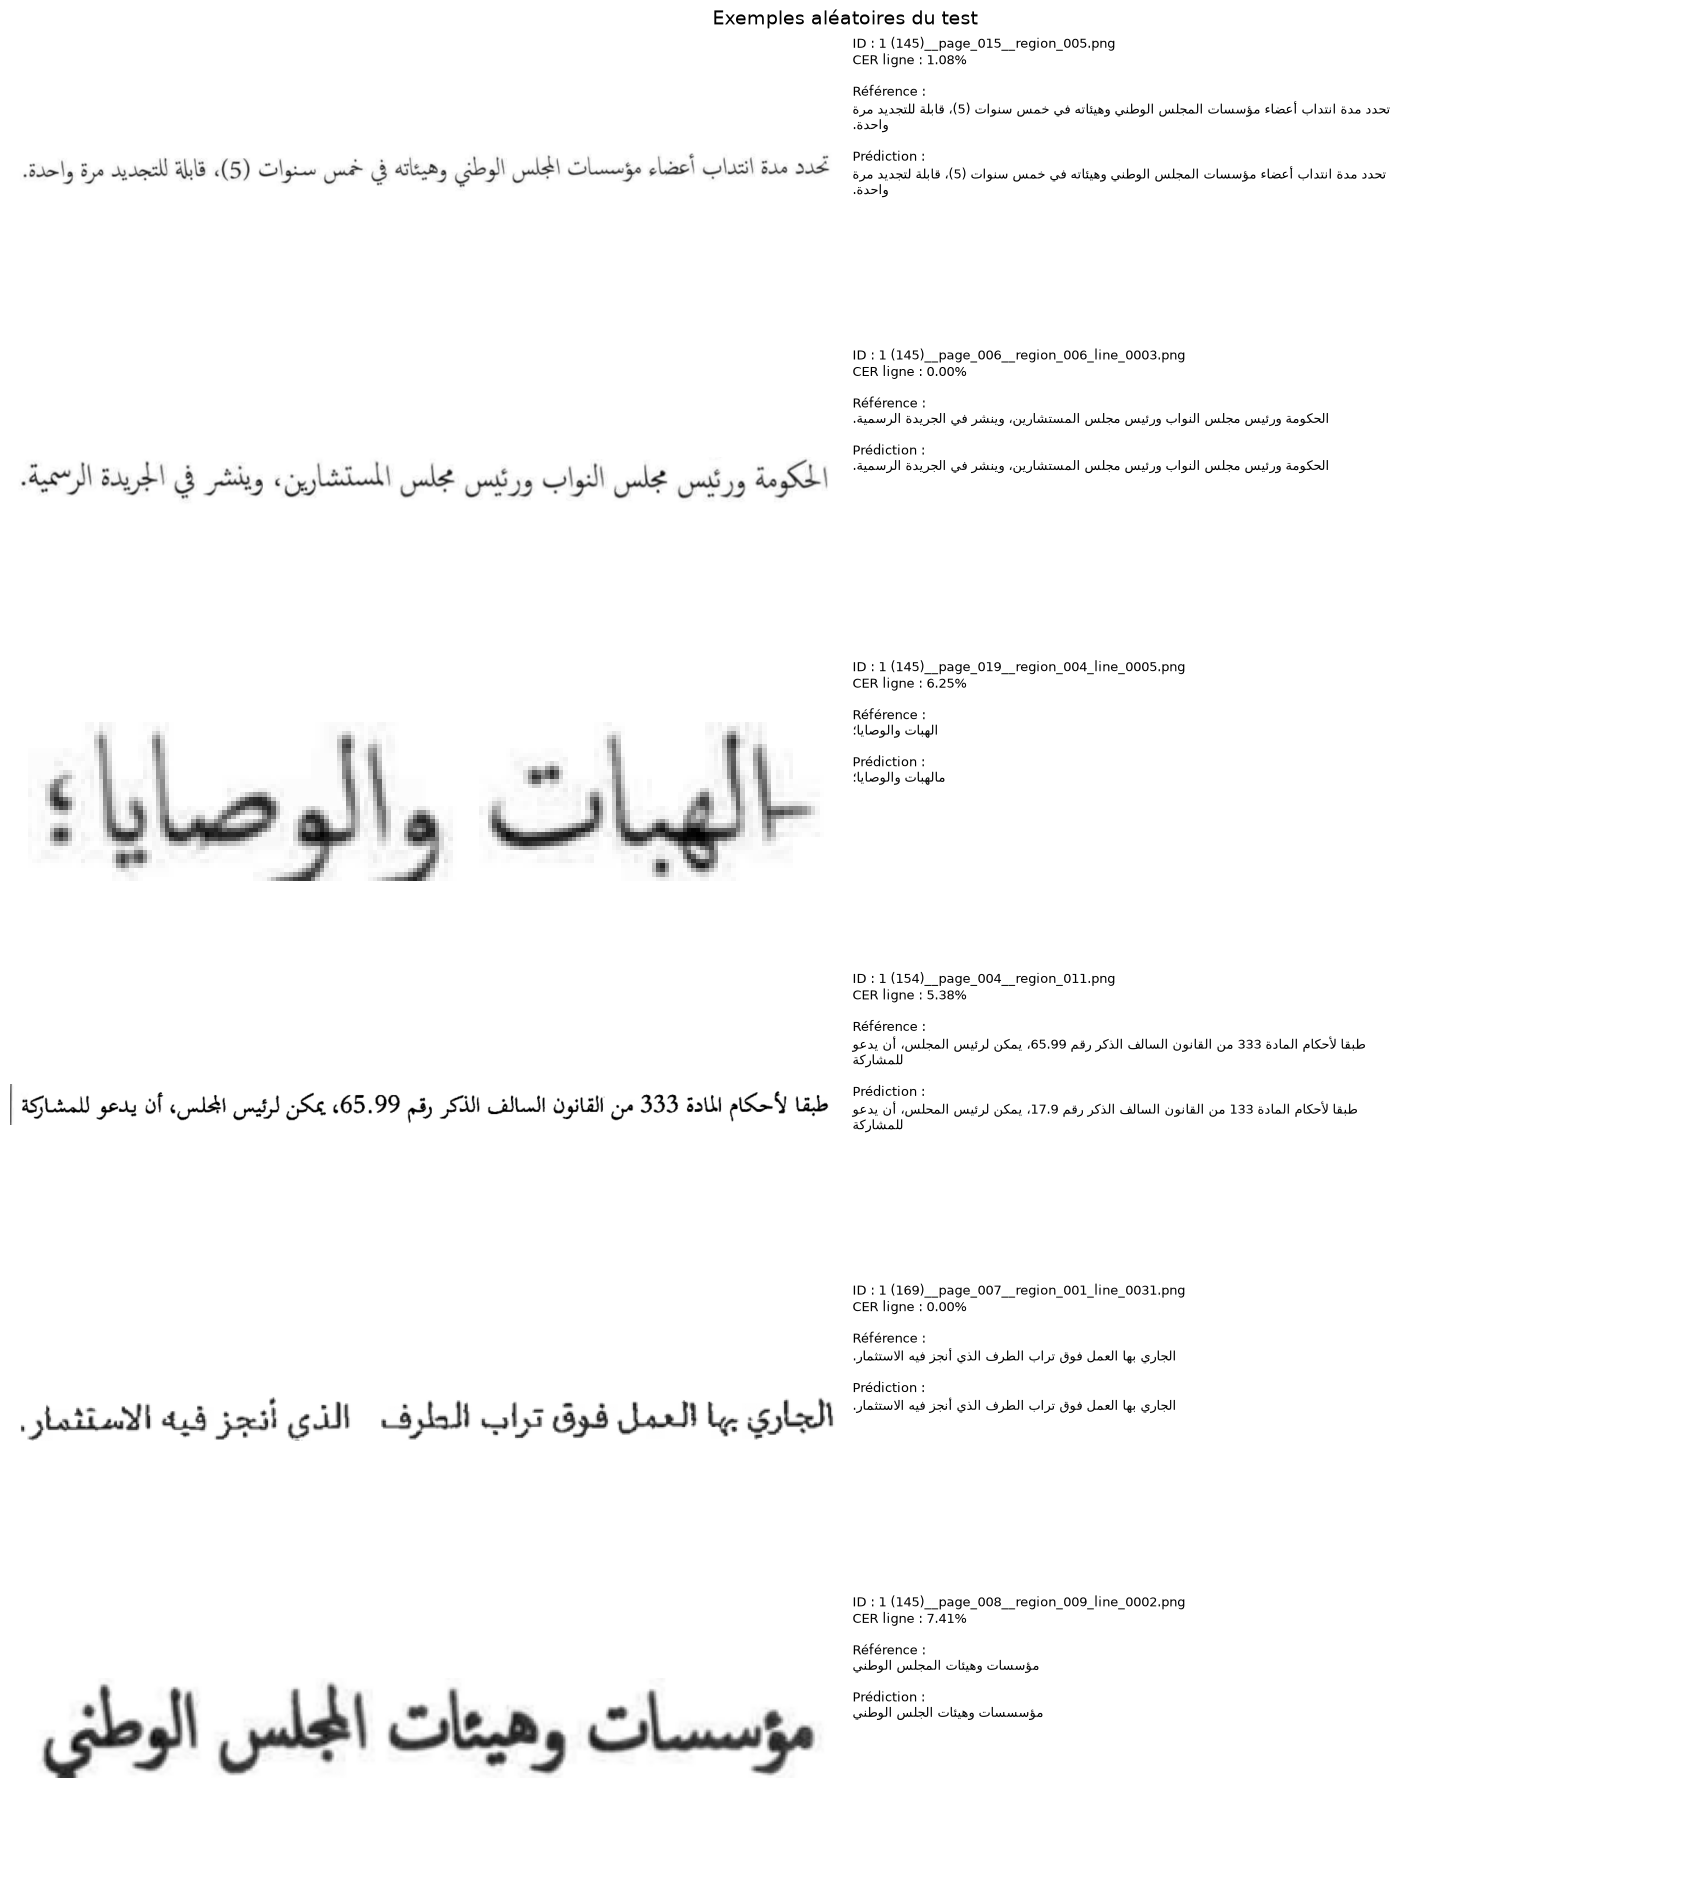

In [4]:
def show_gallery(selection, title, output_path=None, columns=2):
    selection = selection.reset_index(drop=True)
    rows = len(selection)
    fig, axes = plt.subplots(rows, columns, figsize=(17, max(4, rows * 3.2)), squeeze=False)
    for index, (_, item) in enumerate(selection.iterrows()):
        axis = axes[index, 0]
        with Image.open(item['image']) as image:
            axis.imshow(image.convert('L'), cmap='gray')
        axis.axis('off')
        reference = textwrap.fill(str(item['text']), 90)
        prediction = textwrap.fill(str(item['prediction']) if item['prediction'] else '(non disponible)', 90)
        error = 'n/a' if pd.isna(item['line_cer']) else f"{item['line_cer']:.2%}"
        axes[index, 1].axis('off')
        axes[index, 1].text(0, .95, f"ID : {item['id']}\nCER ligne : {error}\n\nRéférence :\n{reference}\n\nPrédiction :\n{prediction}", va='top', fontsize=9, wrap=True)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    if output_path:
        output_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(output_path, dpi=160, bbox_inches='tight', facecolor='white')
        print('Galerie enregistrée :', output_path)
    plt.show()

random_examples = df.sample(6, random_state=42)
show_gallery(random_examples, 'Exemples aléatoires du test')

Galerie enregistrée : C:\Users\sail_\Documents\Codex\2026-10-29\oui-il-existe-des-datasets-adapt\outputs\arabic_ocr\runs\baseline\test\test_images_transcriptions_gallery.png


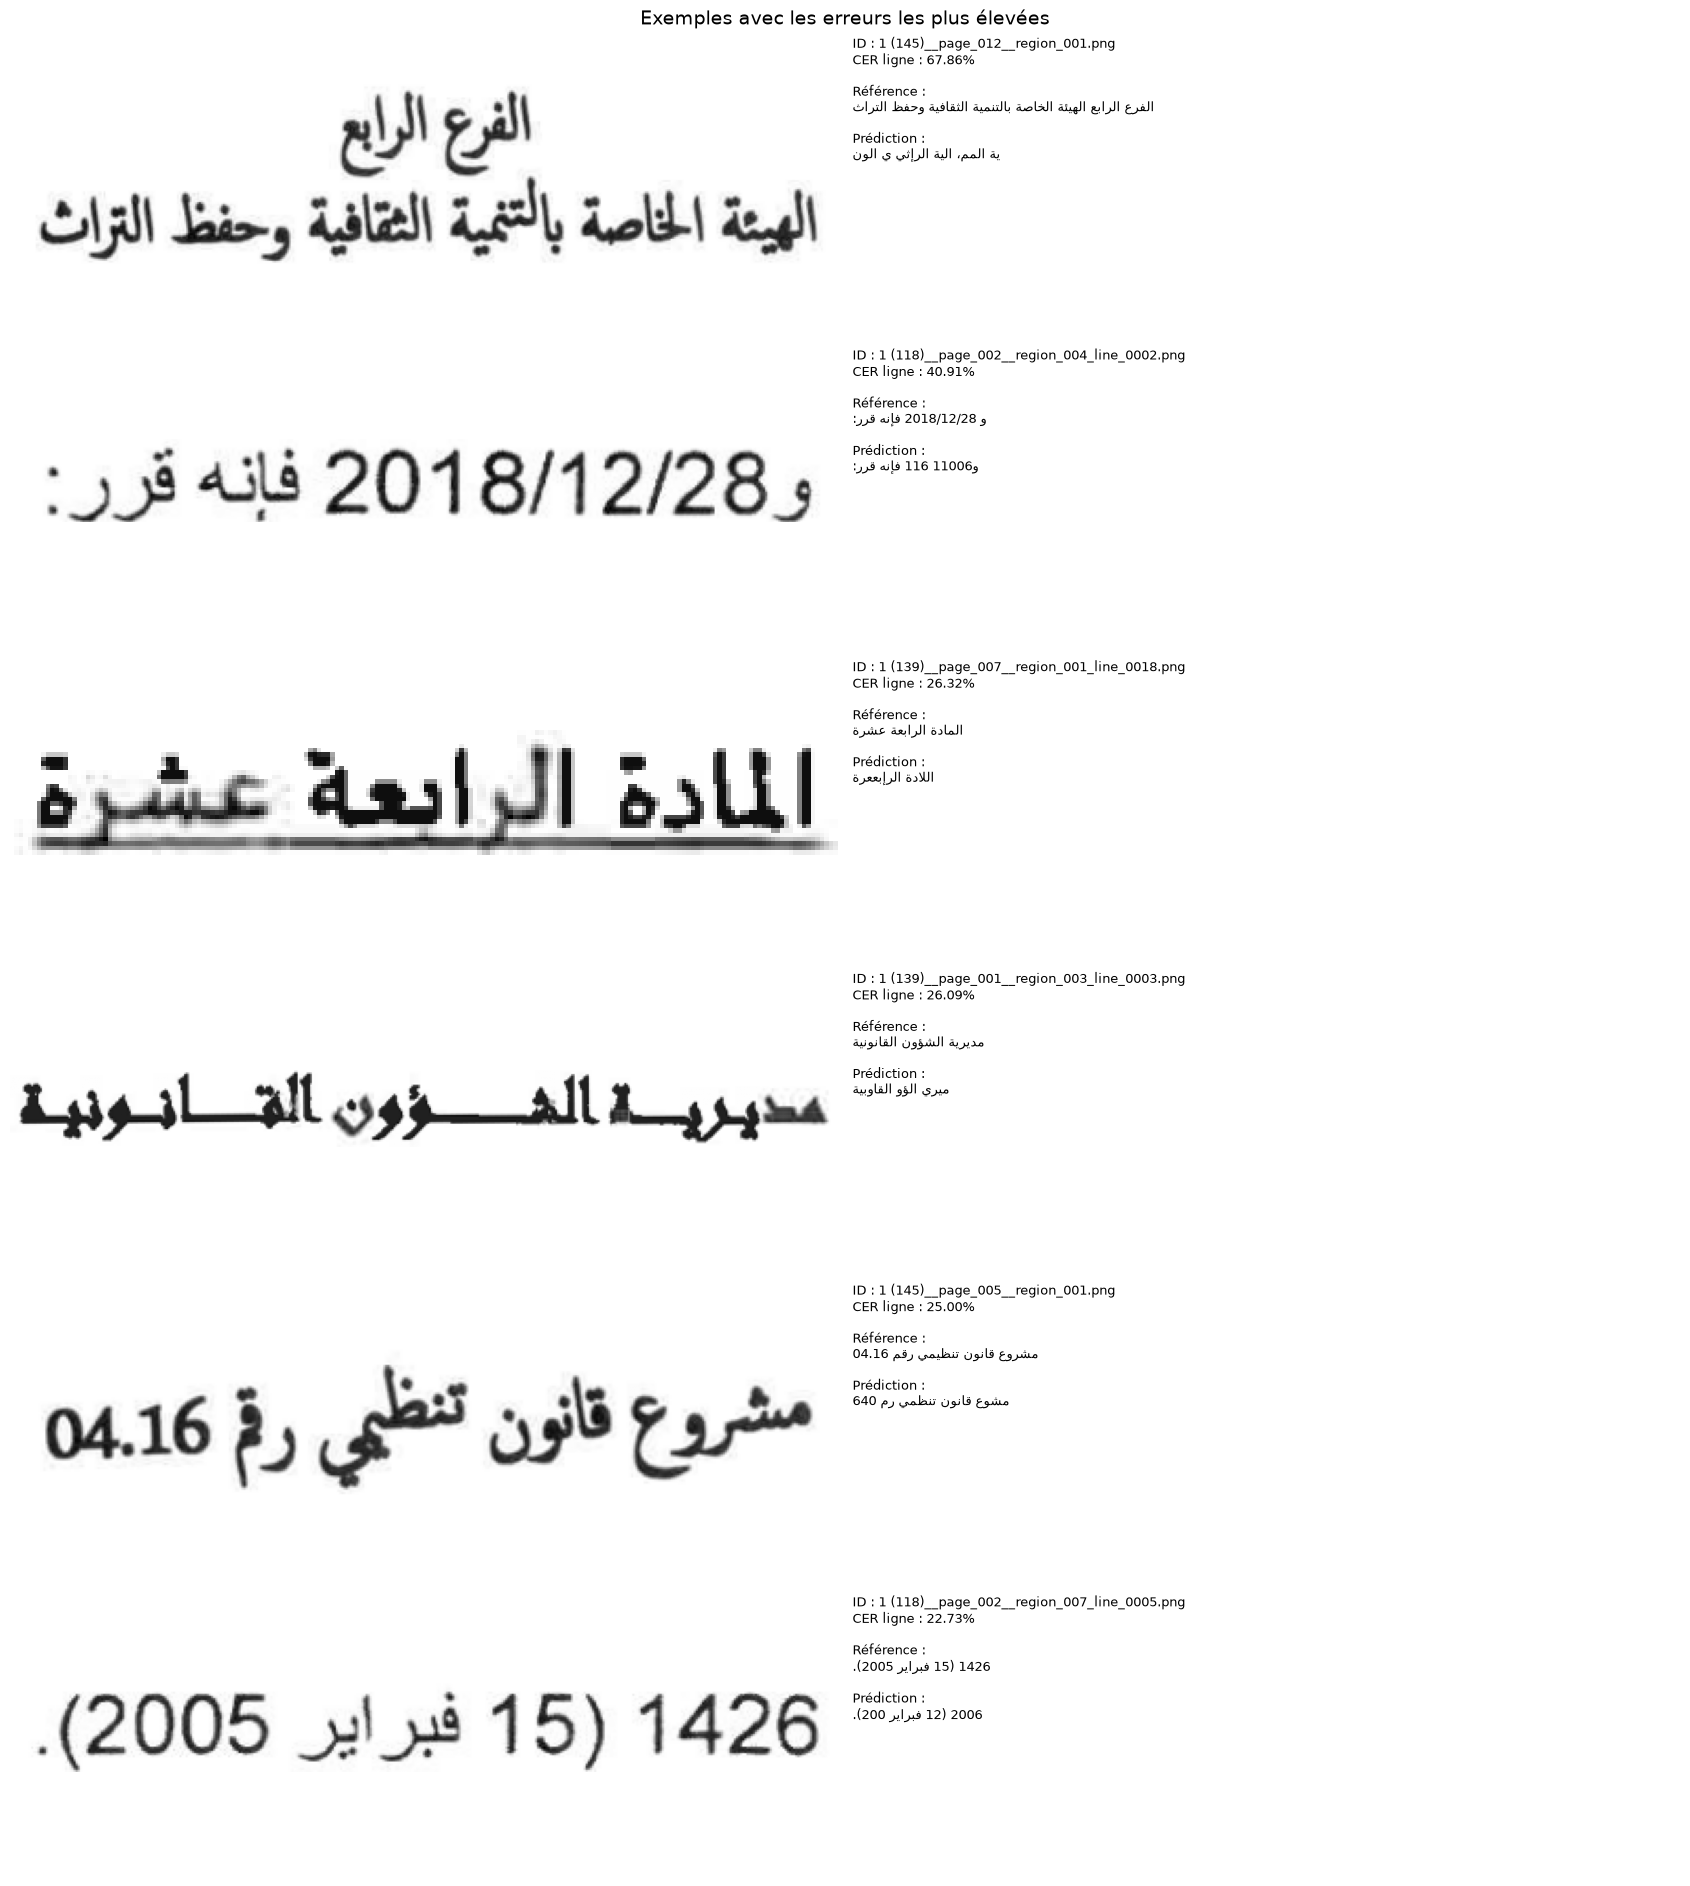

In [5]:
if df['line_cer'].notna().any():
    hardest = df.sort_values(['line_cer', 'id'], ascending=[False, True]).head(6)
    show_gallery(hardest, 'Exemples avec les erreurs les plus élevées', RUN / 'test' / 'test_images_transcriptions_gallery.png')
else:
    print('Lancez evaluate.py avant cette cellule pour générer la galerie des erreurs.')